<a href="https://colab.research.google.com/github/HanMaria/Project/blob/main/Commodity_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import

In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import os
import joblib
import polars as pl # is used for creating polar plots and set up polar axes. It allows us to plot data with using angular ($\theta$) and radius ($r$)
                    # coordinates rather than standard Cartesian (x, y) coordinates
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
from functools import partial

import warnings
warnings.filterwarnings('ignore')

## Data Load

In [2]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle competitions download -c mitsui-commodity-prediction-challenge

  0% 0.00/10.4M [00:00<?, ?B/s]
100% 10.4M/10.4M [00:00<00:00, 1.03GB/s]


In [3]:
!unzip /content/mitsui-commodity-prediction-challenge.zip

Archive:  /content/mitsui-commodity-prediction-challenge.zip
  inflating: kaggle_evaluation/__init__.py  
  inflating: kaggle_evaluation/core/__init__.py  
  inflating: kaggle_evaluation/core/base_gateway.py  
  inflating: kaggle_evaluation/core/generated/__init__.py  
  inflating: kaggle_evaluation/core/generated/kaggle_evaluation_pb2.py  
  inflating: kaggle_evaluation/core/generated/kaggle_evaluation_pb2_grpc.py  
  inflating: kaggle_evaluation/core/kaggle_evaluation.proto  
  inflating: kaggle_evaluation/core/relay.py  
  inflating: kaggle_evaluation/core/templates.py  
  inflating: kaggle_evaluation/mitsui_gateway.py  
  inflating: kaggle_evaluation/mitsui_inference_server.py  
  inflating: lagged_test_labels/test_labels_lag_1.csv  
  inflating: lagged_test_labels/test_labels_lag_2.csv  
  inflating: lagged_test_labels/test_labels_lag_3.csv  
  inflating: lagged_test_labels/test_labels_lag_4.csv  
  inflating: target_pairs.csv        
  inflating: test.csv                
  inflat

In [4]:
target_pairs_df = pd.read_csv('/content/target_pairs.csv')
train_df = pd.read_csv('/content/train.csv')
train_labels_df = pd.read_csv('/content/train_labels.csv')

In [5]:
target_pairs_df.iloc[9]

,9
target,target_9
lag,1
pair,FX_AUDJPY - LME_PB_Close


This means what?

in target_pairs_df.iloc[9]


Field | term | mean
| :--- | :---: | ---: |
target | target_9 | We want to predict
lag | 1 | Days into the future
pair | FX_AUDJPY - LME_PB_Close | The asset used


## A bit Analysis and Clearity


In [6]:
lag = 1
day_id = 20 # Target day

train_data = train_df[['FX_AUDJPY','LME_PB_Close']].head(day_id)
target_data = train_labels_df['target_9'].head(day_id)

print(train_data)
print(target_data)

    FX_AUDJPY  LME_PB_Close
0   87.933498        2570.0
1   88.130730        2579.0
2   88.709278        2587.0
3   88.971278        2540.0
4   88.797150        2604.0
5   88.082978        2545.0
6   87.466563        2550.0
7   87.779334        2549.0
8   87.943426        2535.0
9   88.070454        2587.0
10  87.997519        2554.0
11  88.805843        2547.0
12  88.898884        2610.0
13  88.541283        2581.0
14  88.873013        2620.0
15  88.144039        2608.0
16  88.023568        2640.5
17  88.094217        2605.0
18  88.123784        2593.0
19  88.200614        2602.0
0     0.003446
1     0.021284
2    -0.026844
3     0.014843
4    -0.008985
5     0.003962
6     0.007375
7    -0.018862
8     0.012010
9     0.011888
10   -0.023387
11    0.007143
12   -0.011258
13   -0.003646
14   -0.013752
15    0.014338
16    0.004953
17   -0.002593
18    0.002683
19   -0.008574
Name: target_9, dtype: float64


In [7]:
# Training features: up to (day_id - lag) -> day 0 to 18
x_train = train_data.iloc[: day_id - lag]

# Training labels: shifted by lag -> day 1 to 19
y_train = target_data.iloc[lag:day_id]

# To predict day 20 -> uses features from day 19
x_to_predict = train_data.iloc[[day_id - lag]] # i.e., ... row 19

## Data Preparation

In [8]:
def generate_log_returns(data, lag):
  log_returns = pd.Series(np.nan, index=data.index)

  # Compute log returns based on the rules
  for t in range(len(data)):
    with warnings.catch_warnings():
      warnings.simplefilter('ignore')
      try:
        log_returns.iloc[t] = np.log(data.iloc[t + lag + 1] / data.iloc[t + 1])
      except Exception:
        log_returns.iloc[t] = np.nan
  return log_returns

def generate_targets(column_a: pd.Series, column_b: pd.Series, lag:int) -> pd.Series:
  a_returns = generate_log_returns(column_a, lag)
  b_returns = generate_log_returns(column_b, lag)
  return a_returns - b_returns

In [9]:
def get_data_for_day(row, index):
  '''
  Return:
    target_col, x_train, x_test, y_train, y_test

  - row: one row from the target_pairs_df (target, lag, pair)
  - index: integer day index (use len(train_df) - 1 for the latest)
  '''
  target_col = row[0]     # e.g., target_-9
  lag = int(row[1])       # ensure integer
  feature_string = row[2] # e.g. "FX_AUDJPY-LME_PB_Close"

  # Parse features
  feature_list = [p.strip() for p in feature_string.split('-') if p.strip() != '']
  feat_a = feature_list[0]

  # Prepare series_a and series_b (as pandas.Series)
  series_a = train_df[feat_a].iloc[:index].copy()

  if len(feature_list) > 1:
    feat_b = feature_list[1]
    series_b = train_df[feat_b].iloc[:index].copy()
  else:
    # If only one feature presents, use zero (or to optionally use series_a to just return a_returns)
    series_b = pd.Series(0.0, index=train_df.index[:index])

  # Build feature_data using only existing columns
  available_cols = [c for c in feature_list if c in train_df.columns]
  feature_data = train_df[available_cols].iloc[:index].copy()
  feature_data = feature_data.fillna(method='ffill').fillna(method='bfill')

  # Compute raw y_series (may contain NaNs)
  y_series_raw = generate_targets(series_a, series_b, lag)

  # Fill NaNs in the whole target series Before slicing
  # forward-fill then backward-fill is typical for time-series
  y_series = y_series_raw.fillna(method='ffill').fillna(method='bfill')

  # If the entire series is still NaN (edge case), fill with 0
  if y_series.isna().all():
    y_series = pd.Series(0.0, index=y_series_raw.index)

  # Align features and targets (account for lag)
  # x_train uses row [0 ... index - lag - 1] (length = index - lag)
  # y_train uses row [lag ... index - 1] (same length)
  max_idx_for_train = index - lag # exclusive upper bound for x_train iloc

  if max_idx_for_train <= 0:
    # Not enough history to produce training rows - return empty array
    x_train = feature_data.iloc[0:0].copy()
    y_train = pd.Series(dtype=float)

  else:
    x_train = feature_data.iloc[:max_idx_for_train].copy()
    y_train = y_series.iloc[lag:index].copy() # same length as x_train

  # Test feature row: features at time (index - lag)
  test_row_index = index - lag
  # Guard: If test_row_index is out of bounds use last available
  if test_row_index < 0:
    test_row_index = 0
  elif test_row_index >= len(feature_data):
    test_row_index = len(feature_data) - 1

  x_test = feature_data.iloc[[test_row_index]].copy()

  # y_test: target corresponding to prediction time (aligned to how generate_targets is defined)
  # We use the filled series to avoid NaN
  if test_row_index < 0 or test_row_index >= len(feature_data):
    # fallback to last available
    y_test = y_series.iloc[-1]
  else:
    y_test = y_series.iloc[test_row_index]

  # Ensure indices reset for model consumption (optionally)
  x_train = x_train.reset_index(drop=True)
  x_test = x_test.reset_index(drop=True)
  y_train = y_train.reset_index(drop=True) if len(y_train) > 0 else y_train

  return target_col, x_train, x_test, y_train, y_test


def get_test_data_for_day(full_test_df, row):
  target_col = row[0]
  lag = int(row[1])
  feature_string = row[2]

  feature_list = [p.strip() for p in feature_string.split('-')]
  # Ensure it's Pandas
  if hasattr(full_test_df, 'to_pandas'):
    full_test_df = full_test_df.to_pandas()
  test_data = full_test_df[feature_list].fillna(method='ffill').fillna(method='bfill')
  return target_col, test_data

Test the function to see whether it works well

In [10]:
def generate_log_returns(data, lag):
  log_returns = pd.Series(np.nan, index=data.index)

  # Compute log returns based on the rules
  for t in range(len(data)):
    with warnings.catch_warnings():
      warnings.simplefilter('ignore')
      try:
        log_returns.iloc[t] = np.log(data.iloc[t + lag + 1] / data.iloc[t + 1])
      except Exception:
        log_returns.iloc[t] = np.nan
  return log_returns

def generate_targets(column_a: pd.Series, column_b: pd.Series, lag:int) -> pd.Series:
  a_returns = generate_log_returns(column_a, lag)
  b_returns = generate_log_returns(column_b, lag)
  return a_returns - b_returns

def get_data_for_day(row, index):
  '''
  Return:
    target_col, x_train, x_test, y_train, y_test

  - row: one row from the target_pairs_df (target, lag, pair)
  - index: integer day index (use len(train_df) - 1 for the latest)
  '''
  target_col = row[0]     # e.g., target_-9
  lag = int(row[1])       # ensure integer
  feature_string = row[2] # e.g. "FX_AUDJPY-LME_PB_Close"

  # Parse features
  feature_list = [p.strip() for p in feature_string.split('-') if p.strip() != '']
  feat_a = feature_list[0]

  # Prepare series_a and series_b (as pandas.Series)
  series_a = train_df[feat_a].iloc[:index].copy()

  if len(feature_list) > 1:
    feat_b = feature_list[1]
    series_b = train_df[feat_b].iloc[:index].copy() # FIX: Added () to .copy
  else:
    # If only one feature presents, use zero (or to optionally use series_a to just return a_returns)
    series_b = pd.Series(0.0, index=train_df.index[:index])

  # Build feature_data using only existing columns
  available_cols = [c for c in feature_list if c in train_df.columns]
  feature_data = train_df[available_cols].iloc[:index].copy()
  feature_data = feature_data.fillna(method='ffill').fillna(method='bfill')

  # Compute raw y_series (may contain NaNs)
  y_series_raw = generate_targets(series_a, series_b, lag)

  # Fill NaNs in the whole target series Before slicing
  # forward-fill then backward-fill is typical for time-series
  y_series = y_series_raw.fillna(method='ffill').fillna(method='bfill')

  # If the entire series is still NaN (edge case), fill with 0
  if y_series.isna().all():
    y_series = pd.Series(0.0, index=y_series_raw.index)

  # Align features and targets (account for lag)
  # x_train uses row [0 ... index - lag - 1] (length = index - lag)
  # y_train uses row [lag ... index - 1] (same length)
  max_idx_for_train = index - lag # exclusive upper bound for x_train iloc

  if max_idx_for_train <= 0:
    # Not enough history to produce training rows - return empty array
    x_train = feature_data.iloc[0:0].copy()
    y_train = pd.Series(dtype=float)

  else:
    x_train = feature_data.iloc[:max_idx_for_train].copy()
    y_train = y_series.iloc[lag:index].copy() # same length as x_train

  # Test feature row: features at time (index - lag)
  test_row_index = index - lag
  # Guard: If test_row_index is out of bounds use last available
  if test_row_index < 0:
    test_row_index = 0
  elif test_row_index >= len(feature_data):
    test_row_index = len(feature_data) - 1

  x_test = feature_data.iloc[[test_row_index]].copy()

  # y_test: target corresponding to prediction time (aligned to how generate_targets is defined)
  # We use the filled series to avoid NaN
  if test_row_index < 0 or test_row_index >= len(feature_data):
    # fallback to last available
    y_test = y_series.iloc[-1]
  else:
    y_test = y_series.iloc[test_row_index]

  # Ensure indices reset for model consumption (optionally)
  x_train = x_train.reset_index(drop=True)
  x_test = x_test.reset_index(drop=True)
  y_train = y_train.reset_index(drop=True) if len(y_train) > 0 else y_train

  return target_col, x_train, x_test, y_train, y_test


def get_test_data_for_day(full_test_df, row):
  target_col = row[0]
  lag = int(row[1])
  feature_string = row[2]

  feature_list = [p.strip() for p in feature_string.split('-')]
  # Ensure it's Pandas
  if hasattr(full_test_df, 'to_pandas'):
    full_test_df = full_test_df.to_pandas()
  test_data = full_test_df[feature_list].fillna(method='ffill').fillna(method='bfill')
  return target_col, test_data

day_id = 11
row = target_pairs_df.iloc[day_id]
target_col, x_train, x_test, y_train, y_test = get_data_for_day(row, day_id)
print("="*50)
print(x_train)
print("="*50)
print(x_test)
print("="*50)
print(y_train)
print("="*50)
print(y_test)

   FX_EURAUD  LME_CA_Close
0   1.540368        7205.0
1   1.534906        7147.0
2   1.535084        7188.5
3   1.527972        7121.0
4   1.525623        7125.0
5   1.527544        7102.0
6   1.523801        7153.0
7   1.527105        7140.5
8   1.539726        7110.0
9   1.541171        7210.0
   FX_EURAUD  LME_CA_Close
0   1.539837        7078.0
0    0.004791
1   -0.002100
2    0.004492
3   -0.009609
4    0.003915
5    0.012511
6   -0.013029
7    0.017612
8    0.017612
9    0.017612
dtype: float64
0.017611618955177072


## Feature Engineering

|\# | Category | Methods/Examples|
|:---: | :---: | :---|
|**1** |**Lag-based features**| - Simple lags: t-1, t-2, ... <br>- Multiple-step lags (e.g., 7, 30 days) <br>- Seasonal lags (e.g., lag 12 for yearly seasonality)
|**2**|**Rolling/window statistics**| - Rolling mean, median, sum, std, min, max <br>- Rolling quantiles (25%, 75%) <br>- Rolling weighted averages <br>- Rolling correlations between series <br>- Rolling skewness, kurtosis
|**3**|**Differences & rates of change**| - First difference: $x_t - x_{t-1}$ <br>- Percentage change: $\frac{x_t - x_{t-1}}{x_{t-1}}$ <br>- Second differencce <br>- Cumulative change from start/reset
|**4**|**Decomposition-based features**| - Trend, seasonal, residual (e.g., STL) <br>- Seasonal strength/amplitude <br>- Smoothed series (moving average, exponential smoothing)
|**5**|**Calendar/time encodings**| - Day of week, month, quarter, year <br>- Is weekend/holiday <br>- Part of day <br>- Cyclical encoding (sin/cos)
|**6**|**Fourier/frequency features**| - Fourier series terms <br>- Spectral density/ dominant frequency (FFT)
|**7**|**Interaction & polynomial features**| - Multiplying features (e.g., price x volume) <br>- Polynomial terms (e.g., squared, cubed) <br>- Lag x lag interactions
|**8**|**Aggregations over groups**| - Group-by stats (mean, sum, std) by category <br>- Expanding window stats since start
|**9**|**Target encoding (time-aware)**| - Mean/median of target by category **up to current time** (no leakage)
|**10**|**Anomaly / regime indicators**| - Flags for sudden jumps/drops <br>- Regime classification (e.g., high vs. low volatility)

*   Imputation: Forward fill, backfill, interpolate
*   Outliers: Identity, dummy variable
*   Transformation: Log, Box-Cox, seasonal & trend adjustment
*   Encoding: One-hot, Target mean, integer
*   Temporal: Calendar (day, week, month), holidays, cyclical encoding
*   Past features: Lag features, window features both for target and features, lag and window sizes
*   Trend & seasonality: Time variable, changepoint, step changes, Fourier series, seasonal dummies, seasonal lags



In [11]:
def create_lags(data, lags):
  """
  Create lag features for a pandas Series or list

  Parameters:
  -------------
  data : pd.Series or list-like
      The original time-series data.
  lags : int or list of ints
      Lag values (e.g., 1 or [1, 3. 7]).


  Returns:
  ------------
  pd.DataFrame
      Columns named 'lag_(n)' with shifted values.
  """
  s = pd.Series(data).reset_index(drop=True)
  lags = [lags] if isinstance(lags, int) else lags
  lag_df = pd.DataFrame({f'lag_{n}' : s.shift(n) for n in lags})
  return lag_df

In [12]:
def create_rolling_features(data, windows, functions=['mean']):
  """
  Create rolling window features for a pd.Series or list.

  Parameters:
  -------------
  data : pd.Series or list-like
  windows : int or list of ints
      Window sizes (e.g., 3 or [3, 7])
  functions: str or list of str
      Aggregations to compute: 'mean', 'max', 'min, 'std', etc.

  Returns:
  ------------
  pd.DataFrame
      Columns like 'roll_{func}_{w}'.
  """
  s = pd.Series(data).reset_index(drop=True)
  windows = [windows] if isinstance(windows, int) else windows
  functions = [functions] if isinstance(functions, str) else functions

  df = pd.DataFrame()
  for w in windows:
    rolled = s.rolling(window=w)
    for func in functions:
      if hasattr(rolled, func):
        df[f'roll_{func}_{w}'] = getattr(rolled, func)()
      else:
        raise ValueError(f"Unsupported function: {func}")
  return df


In [13]:
def create_diff_feature(data, lags):
  """
  Create difference-from-past features.

  Parameters:
  - data: pd.Series, list, or DataFrame column
  - lags: int or list of ints

  Returns:
  - pd.DataFrame with difference features
  """
  if isinstance(data, list):
    data = pd.Series(data)
  if isinstance(lags, int):
    lags = [lags]

  diff_df = pd.DataFrame()
  for lag in lags:
    diff_df[f'diff_{lag}'] = data.diff(lag)

  return diff_df


In [14]:
s = pd.Series([10, 20, 30, 40, 50, 60])

print(create_lags(s, [1, 2, -1, -2]))
print(create_rolling_features(s, windows=[2,3], functions=['mean', 'max']))
print(create_diff_feature(s, [1, 2, -1, -2]))

   lag_1  lag_2  lag_-1  lag_-2
0    NaN    NaN    20.0    30.0
1   10.0    NaN    30.0    40.0
2   20.0   10.0    40.0    50.0
3   30.0   20.0    50.0    60.0
4   40.0   30.0    60.0     NaN
5   50.0   40.0     NaN     NaN
   roll_mean_2  roll_max_2  roll_mean_3  roll_max_3
0          NaN         NaN          NaN         NaN
1         15.0        20.0          NaN         NaN
2         25.0        30.0         20.0        30.0
3         35.0        40.0         30.0        40.0
4         45.0        50.0         40.0        50.0
5         55.0        60.0         50.0        60.0
   diff_1  diff_2  diff_-1  diff_-2
0     NaN     NaN    -10.0    -20.0
1    10.0     NaN    -10.0    -20.0
2    10.0    20.0    -10.0    -20.0
3    10.0    20.0    -10.0    -20.0
4    10.0    20.0    -10.0      NaN
5    10.0    20.0      NaN      NaN


In [15]:
def prepare_features_for_col(
    col,
    col_name,
    lag_values=None,
    win_values=None,
    win_methods=None,
    diff_values=None,
    is_a_target = False
):
    """
    Generate lag, rolling window, and difference features for a single column.

    Parameters:
    ----------
    col : list, pandas.Series, or numpy.ndarray
        The input column data.
    col_name : str
        Name of the column for naming generated features.
    lag_values : list[int]
        List of lag steps.
    win_values : list[int]
        List of window sizes for rolling features.
    win_methods : list[str]
        Methods for rolling aggregation: 'mean', 'max', 'min', 'sum', etc.
    diff_values : list[int]
        List of periods for calculating differences.

    Returns:
    -------
    pandas.DataFrame
        DataFrame with all generated features.
    """

    # Ensure input is a pandas Series
    if not isinstance(col, pd.Series):
        col = pd.Series(col)

    # Initialize result DataFrame
    features = pd.DataFrame(index=col.index)

    # add col as well
    if not is_a_target:
        features[f"{col_name}"] = col

    # --- Lag Features ---
    if lag_values:
        for lag in lag_values:
            features[f"lag_{lag}_{col_name}"] = col.shift(lag)

    # --- Rolling Window Features ---
    if win_values and win_methods:
        for win in win_values:
            for method in win_methods:
                if hasattr(pd.Series.rolling(col, win), method):
                    features[f"win_{method}_{win}_{col_name}"] = getattr(col.rolling(win), method)()
                else:
                    raise ValueError(f"Method '{method}' is not supported for rolling windows.")

    # --- Difference Features ---
    if diff_values:
        for diff in diff_values:
            features[f"diff_{diff}_{col_name}"] = col.diff(diff)

    return features

df_features = prepare_features_for_col(
    col=s,
    col_name="sales",
    lag_values=[1, 2,-1,-2],
    win_values=[2, 3],
    win_methods=["mean", "max"],
    diff_values=[1, 2,-1,-2]
)
df_features

,sales,lag_1_sales,lag_2_sales,lag_-1_sales,lag_-2_sales,win_mean_2_sales,win_max_2_sales,win_mean_3_sales,win_max_3_sales,diff_1_sales,diff_2_sales,diff_-1_sales,diff_-2_sales
0,10,NaN,NaN,20.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,-10.0,-20.0
1,20,10.0,NaN,30.0,40.0,15.0,20.0,NaN,NaN,10.0,NaN,-10.0,-20.0
2,30,20.0,10.0,40.0,50.0,25.0,30.0,20.0,30.0,10.0,20.0,-10.0,-20.0
3,40,30.0,20.0,50.0,60.0,35.0,40.0,30.0,40.0,10.0,20.0,-10.0,-20.0
4,50,40.0,30.0,60.0,NaN,45.0,50.0,40.0,50.0,10.0,20.0,-10.0,NaN
5,60,50.0,40.0,NaN,NaN,55.0,60.0,50.0,60.0,10.0,20.0,NaN,NaN


In [16]:
def prepare_features_for_df(df, lag_values=None,
                            win_values=None,
                            win_methods=None,
                            diff_values=None):
  to_return = pd.DataFrame()
  for col in list(df.columns):
    featdf = prepare_features_for_col(
        col = df[col],
        col_name = col,
        lag_values = lag_values,
        win_values = win_values,
        win_methods = win_methods,
        diff_values = diff_values
    )
    to_return = pd.concat([to_return, featdf], axis=1)

  to_return = to_return.fillna(method='ffill').fillna(method='bfill')
  return to_return.fillna(method='ffill').fillna(method='bfill')

smpdf = pd.DataFrame(
    {
        "A": [3, 4, 5],
        "B": [4, 5, 6]
    }
)

smpfeatdf = prepare_features_for_df(
    smpdf,
    lag_values=[1, 2, 5, 7, 10, 15, 20, -1, -2, -5, -7, -10, -20],
    win_values=[2, 3, 5, 7, 15, 30],
    win_methods=['mean', 'max'],
    diff_values=[1, 2, 5, 7, 10, 15, 20, -1, -2, -5, -7, -10, -15, -20]
)

smpfeatdf

,A,lag_1_A,lag_2_A,lag_5_A,lag_7_A,lag_10_A,lag_15_A,lag_20_A,lag_-1_A,lag_-2_A,...,diff_10_B,diff_15_B,diff_20_B,diff_-1_B,diff_-2_B,diff_-5_B,diff_-7_B,diff_-10_B,diff_-15_B,diff_-20_B
0,3,3.0,3.0,NaN,NaN,NaN,NaN,NaN,4.0,5.0,...,NaN,NaN,NaN,-1.0,-2.0,NaN,NaN,NaN,NaN,NaN
1,4,3.0,3.0,NaN,NaN,NaN,NaN,NaN,5.0,5.0,...,NaN,NaN,NaN,-1.0,-2.0,NaN,NaN,NaN,NaN,NaN
2,5,4.0,3.0,NaN,NaN,NaN,NaN,NaN,5.0,5.0,...,NaN,NaN,NaN,-1.0,-2.0,NaN,NaN,NaN,NaN,NaN


In [17]:
# Scaling
scaler = StandardScaler()
def scale(df):
  scaled_array = scaler.fit_transform(df)
  scaled_df = pd.DataFrame(scaled_array, columns=df.columns)
  return scaled_df

print(scale(smpfeatdf.fillna(0)).head(2))

# Logging
def log_transform_df(df):
  numeric_cols = df.select_dtypes(include=[np.number]).columns
  df_log = df.copy()
  df_log[numeric_cols] = np.log1p(df_log[numeric_cols]) # log1p = log(x+1)
  return df_log

print(log_transform_df(smpfeatdf).head(2))

          A   lag_1_A  lag_2_A  lag_5_A  lag_7_A  lag_10_A  lag_15_A  \
0 -1.224745 -0.707107      0.0      0.0      0.0       0.0       0.0   
1  0.000000 -0.707107      0.0      0.0      0.0       0.0       0.0   

   lag_20_A  lag_-1_A  lag_-2_A  ...  diff_10_B  diff_15_B  diff_20_B  \
0       0.0 -1.414214       0.0  ...        0.0        0.0        0.0   
1       0.0  0.707107       0.0  ...        0.0        0.0        0.0   

   diff_-1_B  diff_-2_B  diff_-5_B  diff_-7_B  diff_-10_B  diff_-15_B  \
0        0.0        0.0        0.0        0.0         0.0         0.0   
1        0.0        0.0        0.0        0.0         0.0         0.0   

   diff_-20_B  
0         0.0  
1         0.0  

[2 rows x 80 columns]
          A   lag_1_A   lag_2_A  lag_5_A  lag_7_A  lag_10_A  lag_15_A  \
0  1.386294  1.386294  1.386294      NaN      NaN       NaN       NaN   
1  1.609438  1.386294  1.386294      NaN      NaN       NaN       NaN   

   lag_20_A  lag_-1_A  lag_-2_A  ...  diff_10_B  dif

## Model Engineering

In [18]:
def mean_squared_error(preds, trues):
  preds = np.array(preds)
  trues = np.array(trues)
  return np.mean((preds - trues) ** 2)

def train_and_get_result(x_train, y_train, x_test):
  # Define base learners
  base_learners = [
      ('lgbm', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42, verbosity=-1)),
      ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
      ('xgb', XGBRegressor(n_estimators=50, randome_state=42))
  ]
  # Step 1: Train base models and get predictions on training data
  meta_features_train = []
  meta_features_test = []
  base_models = []
  for name, model in base_learners:
    model.fit(x_train, y_train)
    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)
    meta_features_train.append(train_pred.reshape(-1, 1)) # For Stacking
    meta_features_test.append(test_pred.reshape(-1, 1))
    base_models.append(model)

  # Stack base learners' predictions as features for meta-model
  meta_x_train = np.hstack(meta_features_train)
  meta_x_test = np.hstack(meta_features_test)

  # Step 2: Train meta-model (final estimator)
  meta_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
  meta_model.fit(meta_x_train, y_train)

  # Step 3: Predict using meta-model
  final_pred = meta_model.predict(meta_x_test)[0]
  # Optional: Save the meta-model
  joblib.dump(meta_model, 'final_stacked_xgb_model.pkl')
  return final_pred, {'meta_model': meta_model, 'base_models': base_models}

def predict_on_models(model_dict, test):
  base_models = model_dict['base_models']
  meta_model = model_dict["meta_model"]

  # Get base models' predictions on the test input
  meta_features_test = []
  for model in base_models:
    pred = model.predict(test)
    meta_features_test.append(pred.reshape(-1, 1))

  # Ensure 2D shape
  # Stack all base predictions into one feature set
  meta_x_test = np.hstack(meta_features_test)
  # Final predictions using the meta-model
  final_pred = meta_model.predict(meta_x_test)
  return final_pred

def safe_log1p(X):
  X = np.array(X, dtype=float)
  X = np.where(X <= -1, np.nan, X) # avoid log on invalid values
  return np.log1p(X)


In [19]:
day_id = 12
row = target_pairs_df.iloc[day_id]
target_col, x_train, x_test, y_train, y_test = get_data_for_day(row, day_id)
x_train_feat = prepare_features_for_df(
    x_train,
    lag_values = [1, 2, -1, -2],
    win_values = [2, 3],
    win_methods= ['mean', 'max'],
    diff_values = [1, 2, -1, -2]
)
x_test_feat = prepare_features_for_df(
    x_test,
    lag_values = [1, 2, -1, -2],
    win_values = [2, 3],
    win_methods= ['mean', 'max'],
    diff_values = [1, 2, -1, -2]
)
pipeline = Pipeline([
    ('log', FunctionTransformer(safe_log1p, validate=False)),
    ('replace_inf', FunctionTransformer(lambda X: np.where(np.isinf(X), np.nan, X), validate=False)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

x_train_feat_scaled = pipeline.fit_transform(x_train_feat)
x_test_feat_scaled  = pipeline.transform(x_test_feat)

value, model_dict = train_and_get_result(x_train_feat_scaled, y_train, x_test_feat_scaled)
value


np.float32(0.0006459465)

In [20]:
TARGET_MODEL_POOL = {}
TARGET_MODEL_PIPELINE_POOL = {}
TARGET_TRAIN_SCORES = {}

def replace_inf_func(X):
  return np.where(np.isinf(X), np.nan, X)

def train_one_target(row, day_id):
  target_col, x_train, x_test, y_train, y_test = get_data_for_day(row, day_id)

  # Prepare features
  x_train_feat = prepare_features_for_df(
      x_train,
      lag_values = [1, 2, -1, -2],
      win_values=[2, 3],
      win_methods=['mean', 'max'],
      diff_values=[1, 2, -1, -2]
  )

  x_test_feat = prepare_features_for_df(
      x_test,
      lag_values= [1, 2, -1, -2],
      win_values = [2, 3],
      win_methods = ['mean', 'max'],
      diff_values=[1, 2, -1, -2]
  )

  # Build pipeline without lambdas
  pipeline = Pipeline([
      ('log', FunctionTransformer(safe_log1p, validate=False)),
      ('replace_inf', FunctionTransformer(replace_inf_func, validate=False)),
      ('imputer', SimpleImputer(strategy='median')),
      ('scaler', StandardScaler())
  ])

  # Scaled data
  x_train_feat_sc = pipeline.fit_transform(x_train_feat)
  x_test_feat_sc = pipeline.transform(x_test_feat)

  # Train model
  value, model_dict = train_and_get_result(x_train_feat_sc, y_train, x_test_feat_sc)

  y_pred = predict_on_models(model_dict, x_test_feat_sc)

  TARGET_TRAIN_SCORES[target_col] = {
      'y_true': float(y_test),
      'y_pred': float(y_pred[0]),
      'n_train': len(y_train),
      'day_id': day_id,
  }
  return target_col, pipeline, model_dict

# Determine day_id
if len(train_df) >= 2:
  day_id = train_df.index[-2]
else:
  raise ValueError("Not Enough data for training")

rows = [target_pairs_df.iloc[d] for d in range(len(target_pairs_df))]

# Use partial to avoid lambda
with ThreadPoolExecutor(max_workers=len(train_df)) as executor:
  for target_col, pipeline, model_dict in executor.map(partial(train_one_target, day_id=day_id), rows):
    TARGET_MODEL_PIPELINE_POOL[target_col] = pipeline
    TARGET_MODEL_POOL[target_col] = model_dict

/tmp/ipykernel_255/2684283139.py:27: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  target_col = row[0]     # e.g., target_-9
/tmp/ipykernel_255/2684283139.py:28: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  lag = int(row[1])       # ensure integer
/tmp/ipykernel_255/2684283139.py:29: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  feature_string = row[2] # e.g. "FX_AUDJPY-LME_PB_Close"
/tmp/ipykernel_255/2684283139.py:48: FutureWarni

In [21]:
def safe_fillna(df):
  # Replace NaN medians with 0 as fallback
  medians = df.median()
  medians = medians.fillna(0)
  return df.fillna(medians)

def _predict_one_target(row, full_test_df):
  target_col, test_df = get_test_data_for_day(full_test_df, row)

  # Fill before feature creation
  test_df = safe_fillna(test_df)

  # Create features
  test_df_feat = prepare_features_for_df(
      test_df,
      lag_values=[1, 2, -1, -2],
      win_values = [2, 3],
      win_methods = ['mean', 'max'],
      diff_values = [1, 2, -1, -2]
  )

  pipeline = TARGET_MODEL_PIPELINE_POOL[target_col]
  test_df_feat_sc = pipeline.transform(test_df_feat)

  # Predict
  md = TARGET_MODEL_POOL[target_col]
  predictions = predict_on_models(md, test_df_feat_sc)

  return target_col, predictions

predict_invoke_count = 0

def predict_on_test(full_test_df):
  global predict_invoke_count
  print(f'predict invoked {predict_invoke_count}')
  rows = [target_pairs_df.iloc[t] for t in range(len(target_pairs_df))]
  preds_dict = {}

  with ThreadPoolExecutor() as executor:
    for target_col, predictions in executor.map(lambda row: _predict_one_target(row, full_test_df), rows):
      preds_dict[target_col] = predictions

  preds_df = pd.DataFrame(preds_dict)
  preds_df.to_parquet('submission.parquet', index=False)
  predict_invoke_count += 1
  return preds_df

In [22]:
preds_for_test_set = predict_on_test(pd.read_csv('/content/test.csv'))
preds_for_test_set.sample(5)

predict invoked 0


,target_0,target_1,target_2,target_3,target_4,target_5,target_6,target_7,target_8,target_9,...,target_414,target_415,target_416,target_417,target_418,target_419,target_420,target_421,target_422,target_423
99,0.0,0.003826,-0.010512,0.008328,0.002057,-0.026029,-0.007359,0.000208,-0.001986,-0.009999,...,0.009209,-0.002116,0.001724,0.045737,-0.011911,-0.015427,0.013829,-0.017635,0.062976,-0.057048
94,0.0,0.001373,0.002531,0.009143,0.001228,-0.015713,-0.006613,-0.000545,0.002158,-0.005544,...,-0.012731,-0.002596,-0.017589,0.052411,0.017722,-0.003957,-0.005720,0.020004,0.057023,-0.087164
111,0.0,-0.000692,-0.007823,-0.000115,0.020365,0.010856,-0.003614,0.001564,0.013872,-0.004422,...,0.008424,-0.016496,-0.011681,0.028381,0.017582,0.000788,0.007667,0.006863,0.017603,-0.064403
6,0.0,-0.005932,0.002189,-0.002177,0.005933,-0.005166,-0.000245,-0.005034,0.018887,-0.014565,...,-0.000677,-0.014525,0.017623,0.006465,-0.001715,0.008327,0.004732,0.015498,-0.013348,-0.012591
79,0.0,0.002079,-0.017562,-0.006037,0.030087,0.014298,-0.012067,0.028302,0.019383,-0.014103,...,0.026766,0.016941,-0.021270,0.039913,0.001448,0.024984,0.019024,0.006406,0.046730,-0.000177


## Evaluation

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np # Import numpy for sqrt

scores_df = pd.DataFrame.from_dict(TARGET_TRAIN_SCORES, orient='index')

mae = mean_absolute_error(scores_df['y_true'], scores_df['y_pred'])
mse = mean_squared_error(scores_df['y_true'], scores_df['y_pred'])
rmse = np.sqrt(mse) # Calculate RMSE manually
r2 = r2_score(scores_df['y_true'], scores_df['y_pred'])
corr = scores_df['y_true'].corr(scores_df['y_pred'])

print(f"MAE   : {mae:.5f}")
print(f'RMSE  : {rmse:.5f}')
print(f'R2    : {r2:.5f}')
print(f'Corr  : {corr:.5f}')

MAE   : 0.01965
RMSE  : 0.02937
R2    : -0.11699
Corr  : 0.08547


MAE 0.019646919461654946


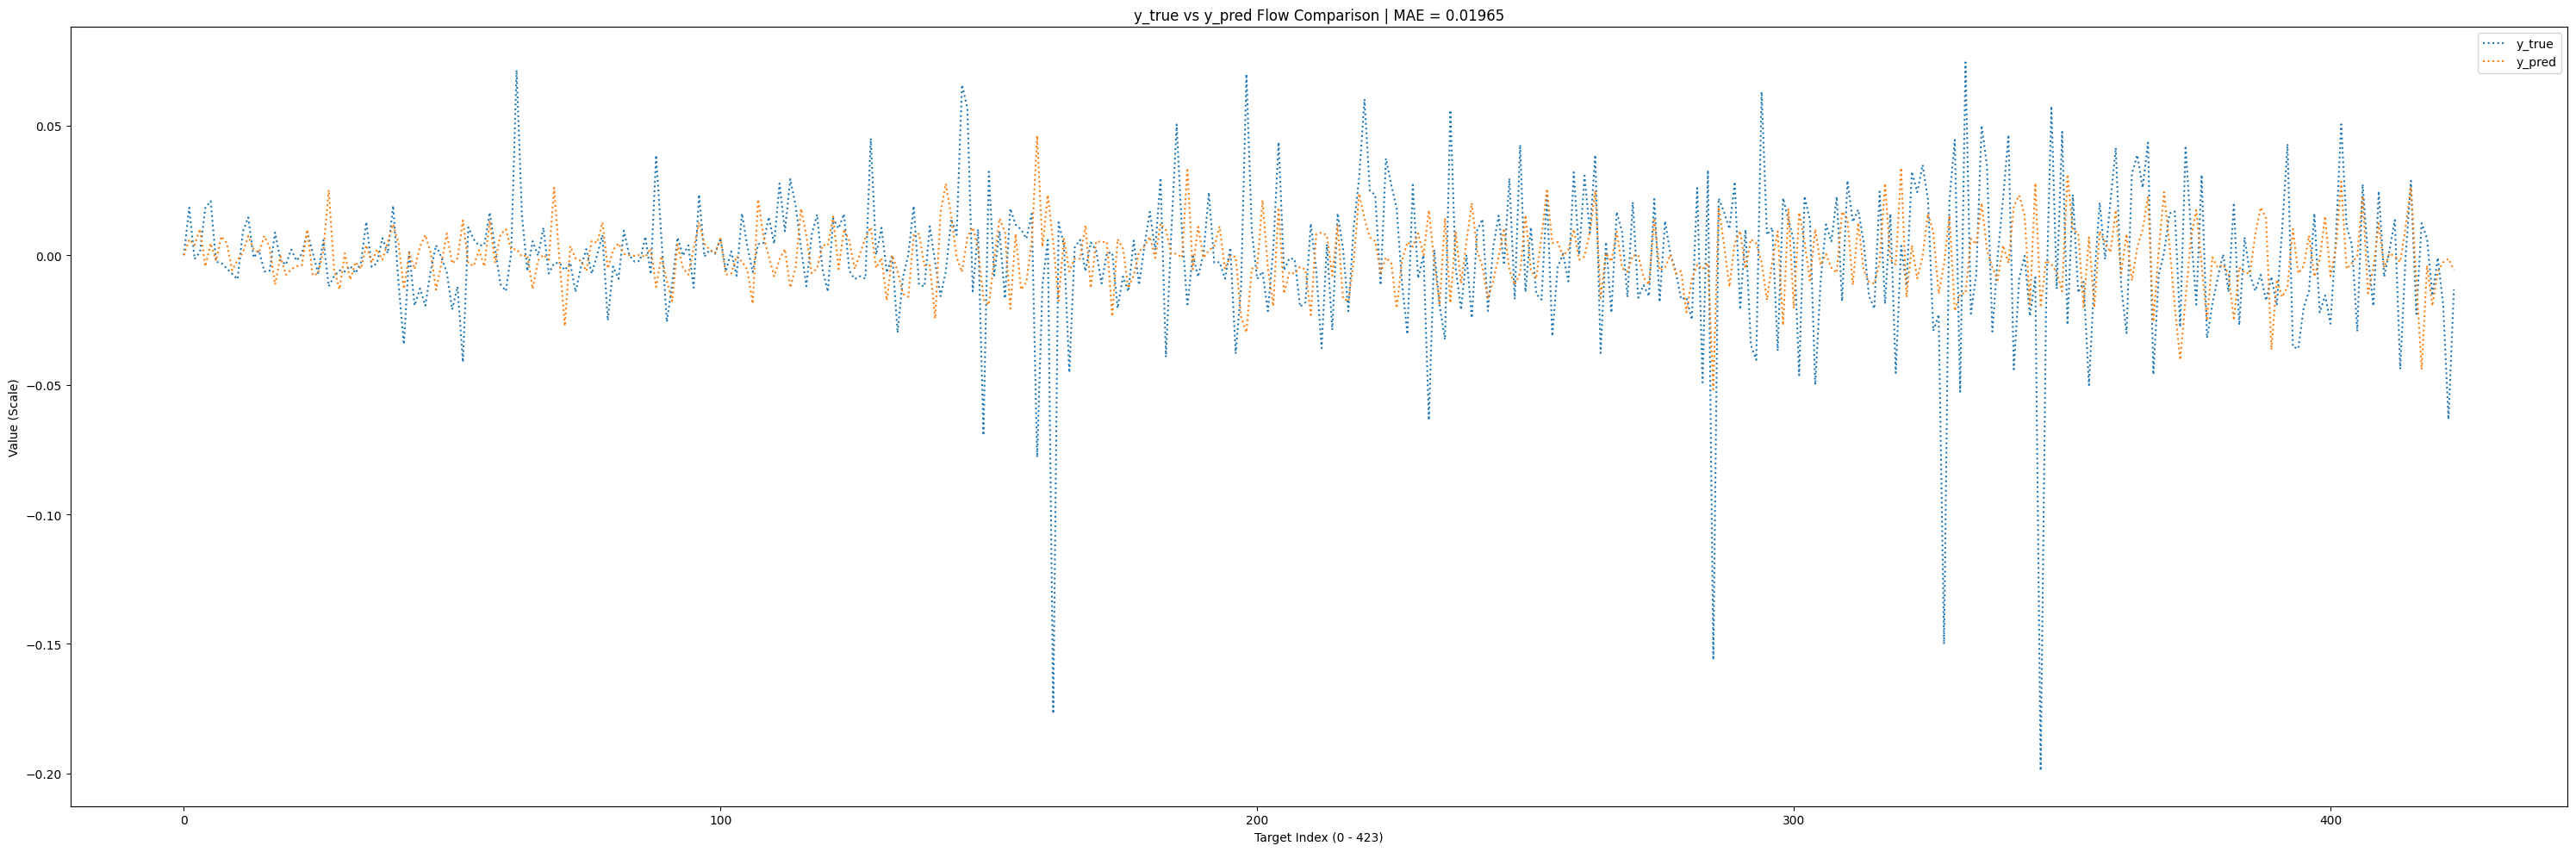

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# MAE (as we already computed)
mae = mean_absolute_error(scores_df['y_true'], scores_df['y_pred'])
print("MAE", mae)

# Reset index to ensure 0...423 on x-axis
scores_df = scores_df.reset_index(drop=True)

plt.figure(figsize=(30, 10))

sns.lineplot(
    x = scores_df.index,
    y = scores_df['y_true'],
    label='y_true',
    linestyle='dotted'
)

sns.lineplot(
    x = scores_df.index,
    y = scores_df['y_pred'],
    label='y_pred',
    linestyle='dotted'
)

plt.xlabel('Target Index (0 - 423)')
plt.ylabel('Value (Scale)')
plt.title(f'y_true vs y_pred Flow Comparison | MAE = {mae:.5f}')
plt.legend()
plt.tight_layout()
plt.show()

## Submission

In [25]:
import sys
sys.path.append('/kaggle/working')

In [26]:
def predict(
    test: pl.DataFrame,
    label_lags_1_batch: pl.DataFrame,
    label_lags_2_batch: pl.DataFrame,
    label_lags_3_batch: pl.DataFrame,
    label_lags_4_batch: pl.DataFrame,
) -> pd.DataFrame:
    # Convert Polars to Pandas
    test = test.to_pandas()
    label_lags_1_batch = label_lags_1_batch.to_pandas()
    label_lags_2_batch = label_lags_2_batch.to_pandas()
    label_lags_3_batch = label_lags_3_batch.to_pandas()
    label_lags_4_batch = label_lags_4_batch.to_pandas()
    return predict_on_test(test)


In [27]:
import polars as pl

try:
  polars_test_df = pl.read_csv('/content/test.csv')
  display(polars_test_df.head())
except Exception as e:
  print(f"Error reading test.csv with Polars: {e}")

date_id,LME_AH_Close,LME_CA_Close,LME_PB_Close,LME_ZS_Close,JPX_Gold_Mini_Futures_Open,JPX_Gold_Rolling-Spot_Futures_Open,JPX_Gold_Standard_Futures_Open,JPX_Platinum_Mini_Futures_Open,JPX_Platinum_Standard_Futures_Open,JPX_RSS3_Rubber_Futures_Open,JPX_Gold_Mini_Futures_High,JPX_Gold_Rolling-Spot_Futures_High,JPX_Gold_Standard_Futures_High,JPX_Platinum_Mini_Futures_High,JPX_Platinum_Standard_Futures_High,JPX_RSS3_Rubber_Futures_High,JPX_Gold_Mini_Futures_Low,JPX_Gold_Rolling-Spot_Futures_Low,JPX_Gold_Standard_Futures_Low,JPX_Platinum_Mini_Futures_Low,JPX_Platinum_Standard_Futures_Low,JPX_RSS3_Rubber_Futures_Low,JPX_Gold_Mini_Futures_Close,JPX_Gold_Rolling-Spot_Futures_Close,JPX_Gold_Standard_Futures_Close,JPX_Platinum_Mini_Futures_Close,JPX_Platinum_Standard_Futures_Close,JPX_RSS3_Rubber_Futures_Close,JPX_Gold_Mini_Futures_Volume,JPX_Gold_Rolling-Spot_Futures_Volume,JPX_Gold_Standard_Futures_Volume,JPX_Platinum_Mini_Futures_Volume,JPX_Platinum_Standard_Futures_Volume,JPX_RSS3_Rubber_Futures_Volume,JPX_Gold_Mini_Futures_settlement_price,JPX_Gold_Rolling-Spot_Futures_settlement_price,…,FX_CADJPY,FX_CHFJPY,FX_EURAUD,FX_EURGBP,FX_EURJPY,FX_EURUSD,FX_GBPAUD,FX_GBPJPY,FX_GBPUSD,FX_NZDJPY,FX_NZDUSD,FX_USDCHF,FX_USDJPY,FX_ZARJPY,FX_ZARUSD,FX_NOKUSD,FX_NOKEUR,FX_CADUSD,FX_AUDNZD,FX_EURCHF,FX_EURCAD,FX_AUDCAD,FX_GBPCHF,FX_EURNZD,FX_AUDCHF,FX_GBPNZD,FX_GBPCAD,FX_CADCHF,FX_NZDCAD,FX_NZDCHF,FX_ZAREUR,FX_NOKGBP,FX_NOKCHF,FX_ZARCHF,FX_NOKJPY,FX_ZARGBP,is_scored
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
1827,2684.5,9190.0,1967.0,2942.0,13623.0,13920.0,13618.0,4696.0,4692.0,386.5,13706.0,13999.0,13710.0,4696.0,4692.0,387.7,13589.0,13870.0,13590.0,4612.5,4615.0,382.1,13640.0,13927.0,13641.0,4615.0,4622.0,384.9,6756.0,2926.0,20746.0,748.0,7736.0,401.0,13641.0,13560.0,…,107.898384,170.824373,1.666148,0.847534,161.232629,1.031512,1.965878,190.23739,1.217075,87.234177,0.558095,0.915016,156.30704,8.341009,0.053363,0.087209,0.084545,0.690298,1.109309,0.94385,1.494301,0.896859,1.113643,1.848274,0.566486,2.180767,1.763116,0.631633,0.808485,0.510666,0.051733,0.071654,0.079797,0.048828,13.631347,0.043845,true
1828,2691.5,9275.0,1985.0,2963.5,13640.0,13922.0,13634.0,4613.0,4613.0,384.4,13707.0,13973.0,13713.0,4679.0,4684.0,385.0,13541.5,13834.0,13544.0,4605.5,4609.0,375.5,13669.5,13943.0,13670.0,4643.0,4647.0,375.5,7504.0,2456.0,21993.0,637.0,8499.0,536.0,13670.0,13590.0,…,108.544742,171.3342,1.659081,0.845098,161.777095,1.042036,1.963181,191.429905,1.233035,88.200272,0.568114,0.90613,155.251002,8.380331,0.053979,0.088524,0.084953,0.699156,1.105553,0.94422,1.490419,0.89834,1.11729,1.834202,0.569122,2.1704,1.763604,0.633526,0.812571,0.514785,0.051802,0.071793,0.080214,0.048912,13.743387,0.043778,true
1829,2646.0,9284.5,1971.0,2914.0,13634.0,13923.0,13638.0,4647.0,4632.0,375.6,13680.0,13960.0,13684.0,4649.5,4657.0,383.9,13556.5,13862.0,13558.0,4614.5,4601.0,375.6,13659.0,13957.0,13661.0,4630.0,4633.0,378.5,8146.0,1695.0,26226.0,464.0,5726.0,316.0,13661.0,13613.0,…,108.597768,171.789524,1.661857,0.843407,162.090092,1.040566,1.970409,192.18482,1.233765,88.175738,0.56606,0.906755,155.77101,8.412732,0.054007,0.088375,0.08493,0.697163,1.106149,0.943539,1.492573,0.898135,1.118723,1.838262,0.567762,2.179566,1.769694,0.632156,0.811948,0.513278,0.051902,0.07163,0.080134,0.048971,13.766241,0.043774,true
1830,2634.0,9223.5,1967.0,2900.0,13681.5,13962.0,13680.0,4630.0,4631.0,376.3,13856.0,14164.0,13860.0,4709.5,4716.0,382.3,13649.0,13943.0,13652.0,4616.0,4618.0,376.0,13833.0,14122.0,13828.0,4693.0,4704.0,382.1,9735.0,4489.0,29298.0,565.0,6202.0,336.0,13828.0,13784.0,…,108.683329,172.606076,1.65926,0.845276,162.832695,1.040854,1.96298,192.63852,1.231377,88.593732,0.566306,0.90635,156.441501,8.452231,0.054028,0.088625,0

In [ ]:
from kaggle_evaluation.mitsui_inference_server import MitsuiInferenceServer
inference_server = MitsuiInferenceServer(predict)

if os.getenv('KAGGLE_IS_COMPETITION_RERUN'):
  inference_server.serve()
else:
  # Local testing - only works if test.csv is present
  inference_server.run_local_gateway(('/content/'))